# This entire Jupyter Notebook it's going to be dedicated to study obesity and overweight 

## How is determined that a person has obesity or overweight?


This calculation is based on BMI, "a calculated measure of body weight relative to height. For adults, BMI categories are underweight, healthy weight, overweight, and obesity. BMI is a calculation of a body person's weight (in kilograms) divided by the square of their height (in meters)"(1)


![BMI categories defined by the CDC](../images/bmi_categories.jpg)

*https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html*

In the Behavioral Risk Factor Surveillance System survey from the CDC used in this research, we have Q037 (Percent of adults aged 18 years and older who have an overweight classification) and Q036 (Percent of adults aged 18 years and older who have obesity). In this section we are going to solve questions like:

 • How has evolved obesity and overweight from 2011 to 2024?
 • What States have lower and bigger  overweight percentahe?
 • What is the poblational group with most prevalence?
 • There is a direct correlation with overweight/obesity and income?

questionid  Obesity (BMI 30+)  Overweight (BMI 25-30)  Combined (BMI 25+)
yearstart                                                                
2011                     27.4                    35.8                63.2
2012                     27.7                    35.7                63.4
2013                     28.3                    35.5                63.8
2014                     28.9                    35.2                64.1
2015                     28.9                    35.7                64.6
2016                     29.6                    35.2                64.8
2017                     30.1                    35.3                65.4
2018                     30.9                    35.0                65.9
2019                     31.4                    35.2                66.6
2020                     31.9                    34.8                66.7
2021                     33.0                    34.4                67.4
2022                     33.3         

C:\Users\Juan David Castillo\AppData\Local\Temp\ipykernel_10912\1424021815.py:4: DtypeWarning: Columns (9: data_value_unit) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/Data_Cleaned.csv")


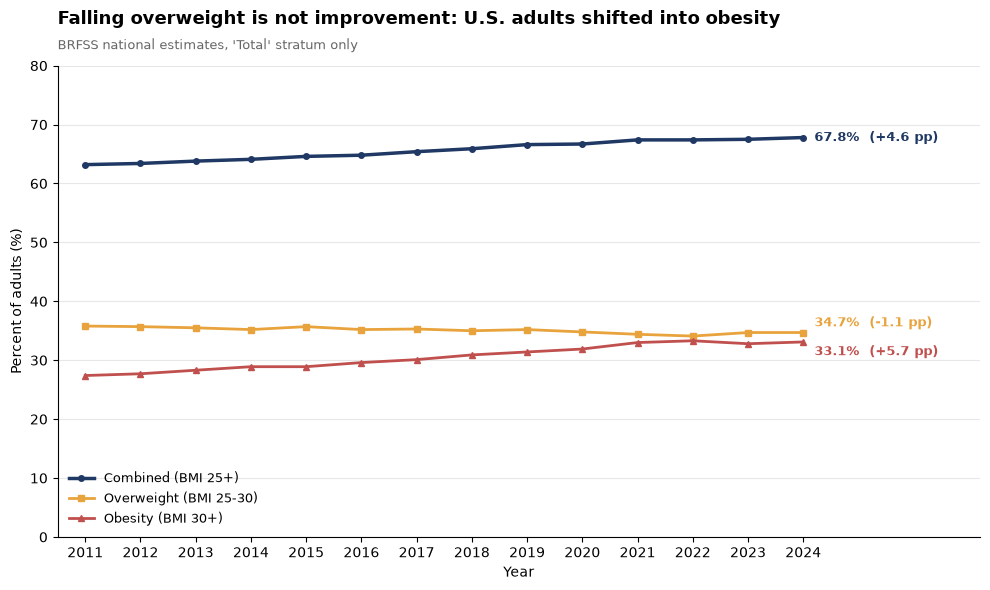

In [7]:
import pandas as pd
import matplotlib.pyplot as plt 

df = pd.read_csv("../data/raw/Data_Cleaned.csv")


WEIGHT_Q = {"Q036": "Obesity (BMI 30+)", "Q037": "Overweight (BMI 25-30)"}

mask = (
    (df["stratificationcategory1"] == "Total")   # sin subgrupos: se solapan
    & (df["locationabbr"] == "US")               # estimación nacional
    & (df["questionid"].isin(WEIGHT_Q))
)
national = df.loc[mask, ["yearstart", "questionid", "data_value"]]

# --- 2. Reshape: una fila por año, una columna por pregunta ---------------
trend = (
    national
    .pivot_table(index="yearstart", columns="questionid", values="data_value")
    .rename(columns=WEIGHT_Q)
    .sort_index()
)
trend["Combined (BMI 25+)"] = trend.sum(axis=1)
print(trend.round(1))

# --- 3. Gráfico ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

styles = {
    "Combined (BMI 25+)":     dict(color="#1F3864", lw=2.5, marker="o", ms=4),
    "Overweight (BMI 25-30)": dict(color="#E8A33D", lw=2.0, marker="s", ms=4),
    "Obesity (BMI 30+)":      dict(color="#C0504D", lw=2.0, marker="^", ms=4),
}
for col, style in styles.items():
    ax.plot(trend.index, trend[col], label=col, **style)

# Etiqueta final con el valor y el cambio acumulado
offsets = {"Combined (BMI 25+)": 0, "Overweight (BMI 25-30)": 7, "Obesity (BMI 30+)": -7}
for col, style in styles.items():
    delta = trend[col].iloc[-1] - trend[col].iloc[0]
    ax.annotate(f"{trend[col].iloc[-1]:.1f}%  ({delta:+.1f} pp)",
                xy=(trend.index[-1], trend[col].iloc[-1]),
                xytext=(8, offsets[col]), textcoords="offset points",
                va="center", fontsize=9, color=style["color"], fontweight="bold")

ax.set_ylim(0, 80)
ax.set_xlim(trend.index.min() - 0.5, trend.index.max() + 3.2)
ax.set_xticks(trend.index)
ax.set_xlabel("Year")
ax.set_ylabel("Percent of adults (%)")
ax.set_title("Falling overweight is not improvement: U.S. adults shifted into obesity",
             fontsize=13, fontweight="bold", loc="left", pad=30)
ax.text(0, 1.035, "BRFSS national estimates, 'Total' stratum only",
        transform=ax.transAxes, fontsize=9, color="#666666")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
#plt.savefig("../reports/figures/weight_trend.png", dpi=130, bbox_inches="tight")
plt.show()





## References
1. https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html, CDC 2024
